Heart Health Information Assistant
1. Develop a labelled corpus containing at least 40 queries across 5 or more intent categories.

In [2]:
!pip -q install nltk scikit-learn seaborn ipywidgets

In [3]:
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

print("Libraries and NLP resources are ready!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Libraries and NLP resources are ready!


In [4]:
corpus = {
    "symptoms": [
        "What are common signs of heart disease?",
        "Why do I feel my heart beating fast?",
        "What can cause palpitations?",
        "Can heart problems cause tiredness?",
        "What are warning signs of an irregular heartbeat?",
        "Why do some people feel dizzy with heart problems?",
        "Can swelling in the ankles be related to the heart?",
        "What symptoms should I discuss with a heart doctor?"
    ],

    "risk_factors": [
        "What increases the risk of heart disease?",
        "Does smoking affect heart health?",
        "Can high blood pressure harm the heart?",
        "Does diabetes increase heart disease risk?",
        "Is family history important for heart disease?",
        "How does high cholesterol affect the heart?",
        "Can stress affect cardiovascular health?",
        "Does being inactive increase heart risk?"
    ],

    "prevention": [
        "How can I keep my heart healthy?",
        "What habits help prevent heart disease?",
        "How can I reduce my risk of a heart attack?",
        "Why are regular health checkups important?",
        "How does quitting smoking help the heart?",
        "Can managing stress protect heart health?",
        "What lifestyle changes support a healthy heart?",
        "How can I improve my cardiovascular health?"
    ],

    "diet": [
        "What foods are good for heart health?",
        "Should I reduce salt in my food?",
        "Which foods contain healthy fats?",
        "Is eating fruits helpful for the heart?",
        "What is a heart healthy diet?",
        "Should I avoid trans fats?",
        "Are whole grains good for cardiovascular health?",
        "How can I reduce saturated fat in my meals?"
    ],

    "exercise": [
        "What exercise is good for the heart?",
        "How does walking help heart health?",
        "How often should adults be physically active?",
        "Can cycling improve cardiovascular fitness?",
        "Why is regular exercise important for the heart?",
        "What are examples of moderate physical activity?",
        "Can I start exercising after being inactive?",
        "How can I build an active daily routine?"
    ],

    "monitoring": [
        "How can I monitor my blood pressure?",
        "What does a blood pressure reading mean?",
        "Why should cholesterol be checked?",
        "What is a resting heart rate?",
        "How often should I get a health checkup?",
        "What information should I record before a doctor visit?",
        "How can I track my physical activity?",
        "Why is it useful to monitor blood sugar for heart health?"
    ],

    "medication_safety": [
        "Should I stop my heart medicine if I feel better?",
        "Why is it important to take prescribed medicine as directed?",
        "What should I do if I miss a prescribed dose?",
        "Can I change my medicine dose myself?",
        "Should I ask a doctor before taking a new supplement?",
        "Can medicines have side effects?",
        "Who should I contact about a medicine reaction?",
        "Can I share my prescription medicine with someone?"
    ],

    "doctor_visit": [
        "When should I talk to a cardiologist?",
        "What questions should I ask my heart doctor?",
        "How should I prepare for a cardiology appointment?",
        "What details should I tell my doctor about chest discomfort?",
        "Should I bring my medicine list to the appointment?",
        "What happens during a routine heart checkup?",
        "How do I discuss my family history with a doctor?",
        "When should I arrange a follow up appointment?"
    ]
}

# Convert the dictionary into input texts (X) and labels (y).
queries = []
labels = []

for intent, examples in corpus.items():
    for query in examples:
        queries.append(query)
        labels.append(intent)

print("Total queries:", len(queries))
print("Number of intents:", len(set(labels)))
print("Intent categories:", list(corpus.keys()))

Total queries: 64
Number of intents: 8
Intent categories: ['symptoms', 'risk_factors', 'prevention', 'diet', 'exercise', 'monitoring', 'medication_safety', 'doctor_visit']


2. Create a hierarchical taxonomy with at least 4 major categories and 2 subcategories under each.

In [5]:
taxonomy = {
    "Heart Information": ["symptoms", "risk_factors"],
    "Healthy Lifestyle": ["prevention", "diet"],
    "Physical Health Tracking": ["exercise", "monitoring"],
    "Medical Guidance": ["medication_safety", "doctor_visit"]
}

for major_category, subcategories in taxonomy.items():
    print(major_category)
    for subcategory in subcategories:
        print("   -", subcategory)

Heart Information
   - symptoms
   - risk_factors
Healthy Lifestyle
   - prevention
   - diet
Physical Health Tracking
   - exercise
   - monitoring
Medical Guidance
   - medication_safety
   - doctor_visit


3. Identify at least 8 domain concepts and define at least 10 relationships among them.

In [6]:
ontology = {
    "Person": {
        "has": ["Blood Pressure", "Heart Rate", "Lifestyle"],
        "may_have": ["Risk Factor"]
    },
    "Heart": {
        "is_affected_by": ["Blood Pressure", "Cholesterol", "Lifestyle"],
        "is_monitored_by": ["Heart Rate"]
    },
    "Doctor": {
        "checks": ["Heart", "Blood Pressure"],
        "advises": ["Lifestyle", "Medication"]
    },
    "Medication": {
        "is_prescribed_by": ["Doctor"],
        "must_be_used_as": ["Prescription"]
    },
    "Lifestyle": {
        "includes": ["Diet", "Exercise"],
        "can_influence": ["Heart"]
    }
}

print("ONTOLOGY RELATIONSHIPS")
for concept, relations in ontology.items():
    for relation, related_concepts in relations.items():
        for related_concept in related_concepts:
            print(concept, "--", relation, "-->", related_concept)

ONTOLOGY RELATIONSHIPS
Person -- has --> Blood Pressure
Person -- has --> Heart Rate
Person -- has --> Lifestyle
Person -- may_have --> Risk Factor
Heart -- is_affected_by --> Blood Pressure
Heart -- is_affected_by --> Cholesterol
Heart -- is_affected_by --> Lifestyle
Heart -- is_monitored_by --> Heart Rate
Doctor -- checks --> Heart
Doctor -- checks --> Blood Pressure
Doctor -- advises --> Lifestyle
Doctor -- advises --> Medication
Medication -- is_prescribed_by --> Doctor
Medication -- must_be_used_as --> Prescription
Lifestyle -- includes --> Diet
Lifestyle -- includes --> Exercise
Lifestyle -- can_influence --> Heart


4. Implement lowercase conversion, tokenization, stopword removal and lemmatization.

In [7]:
def preprocess_text(text):

    text = text.lower()

    tokens = re.findall(r"[a-z]+", text)

    tokens = [word for word in tokens if word not in stop_words]

    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    return " ".join(tokens)

sample = "How can I improve my heart health by walking?"
print("Original sentence:", sample)
print("Processed sentence:", preprocess_text(sample))

Original sentence: How can I improve my heart health by walking?
Processed sentence: improve heart health walking


5. Apply TF-IDF for feature extraction and train a classifier using Naive Bayes, Logistic Regression or
SVM.

In [8]:

clean_queries = [preprocess_text(query) for query in queries]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    clean_queries,
    labels,
    test_size=0.25,
    random_state=42,
    stratify=labels
)

vectorizer = TfidfVectorizer(ngram_range=(1, 2))
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

model = MultinomialNB()
model.fit(X_train, y_train)

print("TF-IDF feature extraction completed.")
print("Naive Bayes model training completed.")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

TF-IDF feature extraction completed.
Naive Bayes model training completed.
Training samples: 48
Testing samples: 16


6. Evaluate the model using accuracy, precision, recall, F1-score and a confusion matrix.

MODEL EVALUATION
Accuracy  : 0.2500
Precision : 0.1750
Recall    : 0.2500
F1-score  : 0.1964

Classification Report:
                   precision    recall  f1-score   support

             diet       0.00      0.00      0.00         2
     doctor_visit       0.00      0.00      0.00         2
         exercise       0.00      0.00      0.00         2
medication_safety       1.00      1.00      1.00         2
       monitoring       0.00      0.00      0.00         2
       prevention       0.00      0.00      0.00         2
     risk_factors       0.40      1.00      0.57         2
         symptoms       0.00      0.00      0.00         2

         accuracy                           0.25        16
        macro avg       0.17      0.25      0.20        16
     weighted avg       0.17      0.25      0.20        16



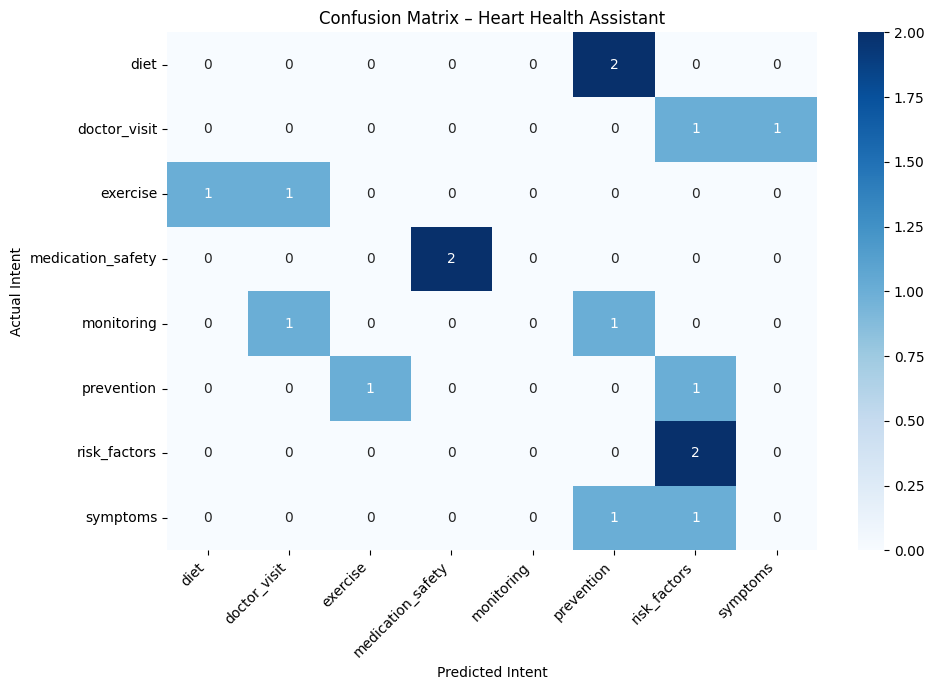

In [9]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

print("MODEL EVALUATION")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
class_names = sorted(set(labels))
cm = confusion_matrix(y_test, y_pred, labels=class_names)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Confusion Matrix – Heart Health Assistant")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

7. Develop a domain-specific knowledge base containing relevant information for each intent category.

In [10]:
knowledge_base = {
    "symptoms": (
        "Heart-related symptoms can vary. Some people may experience chest discomfort, "
        "breathlessness, palpitations, unusual tiredness, dizziness or swelling. "
        "Symptoms can have many causes, so discuss concerns with a qualified healthcare professional."
    ),

    "risk_factors": (
        "Factors associated with heart disease include high blood pressure, high cholesterol, "
        "diabetes, smoking, physical inactivity, an unhealthy diet and family history. "
        "A healthcare professional can help assess your personal risk."
    ),

    "prevention": (
        "Heart-health supporting habits include avoiding tobacco, being physically active, "
        "choosing balanced meals, managing stress, getting adequate sleep and attending "
        "recommended health checkups. Small, consistent changes can help."
    ),

    "diet": (
        "A heart-supportive eating pattern generally includes fruits, vegetables, whole grains, "
        "beans, nuts and suitable sources of healthy fats. Limiting excess salt, added sugar, "
        "trans fats and high amounts of saturated fat may be helpful. Ask a clinician or dietitian "
        "about needs specific to you."
    ),

    "exercise": (
        "Walking, cycling and other activities can support cardiovascular fitness. Start at a "
        "comfortable level and increase activity gradually. If you have a health condition, symptoms "
        "or concerns about exercise, ask a healthcare professional what is safe for you."
    ),

    "monitoring": (
        "Blood pressure, cholesterol, blood sugar and other health measurements can help a clinician "
        "understand cardiovascular risk. Use reliable equipment and follow professional advice about "
        "how often to measure and what your results mean."
    ),

    "medication_safety": (
        "Take medicines only as prescribed. Do not stop, start, share or change a dose on your own. "
        "If you miss a dose, notice a side effect or have questions, contact your prescribing doctor "
        "or pharmacist for instructions specific to that medicine."
    ),

    "doctor_visit": (
        "For a medical appointment, consider noting your symptoms, when they occur, your medical and "
        "family history, and all medicines or supplements you use. Ask the clinician which tests or "
        "follow-up steps are appropriate."
    )
}

print("Knowledge base created for", len(knowledge_base), "intent categories.")

Knowledge base created for 8 intent categories.


8. Implement at least 5 rules, including emergency escalation, low-confidence handling and
unsupported-query handling.

In [11]:

emergency_phrases = [
    "chest pain",
    "chest pressure",
    "severe chest discomfort",
    "shortness of breath",
    "cannot breathe",
    "difficulty breathing",
    "fainting",
    "passed out",
    "stroke",
    "face drooping",
    "one side weakness",
    "sudden weakness",
    "severe sweating"
]

heart_health_terms = {
    "heart", "cardiac", "cardiovascular", "blood", "pressure", "pulse",
    "cholesterol", "chest", "breath", "breathing", "diet", "exercise",
    "walking", "smoking", "diabetes", "medicine", "medication", "doctor",
    "cardiologist", "symptom", "risk", "healthy", "health", "attack",
    "stroke", "dizzy", "palpitation", "salt", "fat", "checkup"
}

def is_emergency(query):
    query_lower = query.lower()
    return any(phrase in query_lower for phrase in emergency_phrases)


def is_supported_domain_query(query):
    words = set(re.findall(r"[a-z]+", query.lower()))
    return len(words.intersection(heart_health_terms)) > 0


def assistant(query, confidence_threshold=0.30):
    query = query.strip()

    if query == "":
        return "Please enter a question about heart health."

    # Rule 1: Emergency escalation takes priority over ML prediction.
    if is_emergency(query):
        return (
            "EMERGENCY ALERT: Your message may describe a serious medical emergency. "
            "Please seek emergency medical help immediately. Do not wait for this chatbot "
            "or use it to assess the symptoms. If you are in India, call 112 or your local "
            "emergency number. Follow the instructions of emergency professionals."
        )

    # Rule 2: Reject questions clearly outside the assistant's domain.
    if not is_supported_domain_query(query):
        return (
            "I am a Heart Health Information Assistant and can answer general questions "
            "about heart health, lifestyle, risk factors, monitoring and medical guidance. "
            "This question appears to be outside my supported topic."
        )

    cleaned_query = preprocess_text(query)

    query_vector = vectorizer.transform([cleaned_query])

    # Rule 3: If no trained vocabulary matches, handle it as unsupported.
    if query_vector.nnz == 0:
        return (
            "I could not understand this question using my current training data. "
            "Please rephrase it using common heart-health terms or consult a healthcare professional."
        )

    probabilities = model.predict_proba(query_vector)[0]
    best_index = np.argmax(probabilities)
    predicted_intent = model.classes_[best_index]
    confidence = probabilities[best_index]

    # Rule 4: Handle low-confidence predictions.
    if confidence < confidence_threshold:
        return (
            "I am not sufficiently confident about the meaning of your question. "
            "Please rephrase it, or ask a qualified healthcare professional."
        )

    # Rule 5: Medication questions receive an additional safety reminder.
    response = knowledge_base[predicted_intent]

    if predicted_intent == "medication_safety":
        response += (
            " Never change a prescribed dose based only on chatbot information."
        )

    return (
        f"Detected intent: {predicted_intent} "
        f"(confidence: {confidence:.2f})\n\n{response}\n\n"
        "Reminder: This is general educational information, not a diagnosis."
    )


print("Heart Health Assistant is ready!")

Heart Health Assistant is ready!


9. Integrate NLP, intent classification, reasoning and knowledge retrieval into a single assistant.

In [14]:
test_queries = [
    "What are common signs of heart disease?",
    "Does smoking affect heart health?",
    "How can I keep my heart healthy?",
    "Should I reduce salt in my food?",
    "How does walking help heart health?",
    "How can I monitor my blood pressure?",
    "Should I stop my heart medicine if I feel better?",
    "What questions should I ask my heart doctor?",
    "What habits keep my cardiovascular system healthy?",
    "What is the best treatment for migraine?",
    "I have crushing chest pain and cannot breathe."
]

for number, question in enumerate(test_queries, start=1):
    print("\nTEST", number)
    print("You:", question)
    print("Assistant:", assistant(question))



TEST 1
You: What are common signs of heart disease?
Assistant: I am not sufficiently confident about the meaning of your question. Please rephrase it, or ask a qualified healthcare professional.

TEST 2
You: Does smoking affect heart health?
Assistant: I am not sufficiently confident about the meaning of your question. Please rephrase it, or ask a qualified healthcare professional.

TEST 3
You: How can I keep my heart healthy?
Assistant: I am not sufficiently confident about the meaning of your question. Please rephrase it, or ask a qualified healthcare professional.

TEST 4
You: Should I reduce salt in my food?
Assistant: I am not sufficiently confident about the meaning of your question. Please rephrase it, or ask a qualified healthcare professional.

TEST 5
You: How does walking help heart health?
Assistant: I am not sufficiently confident about the meaning of your question. Please rephrase it, or ask a qualified healthcare professional.

TEST 6
You: How can I monitor my blood pres

10. Deploy the assistant in Google Colab with an interactive interface that accepts multiple queries and
displays appropriate responses.

In [15]:
import ipywidgets as widgets
from IPython.display import display, clear_output

question_box = widgets.Text(
    value="",
    placeholder="Ask a question about heart health...",
    description="You:",
    layout=widgets.Layout(width="80%")
)

submit_button = widgets.Button(
    description="Submit",
    button_style="primary"
)

chat_output = widgets.Output()

def handle_submit(button):
    question = question_box.value.strip()

    if question == "":
        with chat_output:
            print("Please type a question first.")
        return

    answer = assistant(question)

    with chat_output:
        print("You:", question)
        print("Assistant:", answer)
        print("-" * 80)

    question_box.value = ""

submit_button.on_click(handle_submit)

display(widgets.HBox([question_box, submit_button]))
display(chat_output)

Output()